<a href="https://colab.research.google.com/github/swiftycode256/global_ads_analysis/blob/main/global_ads_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Global Ads Performance — Analysis Notebook
**Data @ NEU · Flurry Track · Fall 2026**
Kelly Xia, Kai Basnyat, Raymond Pu, Gloria Santhosh

**Research questions**
1. Which ad platforms (Google, Meta, TikTok) and which industries/markets get the most engagement (CTR, impressions, clicks)?
2. Do these metrics show a significant upward or downward trend over 2023–2024?
3. Are the differences between platforms statistically significant, or just noise?

**How to use:** download the CSV from Kaggle, run the upload cell, then *Runtime → Run all*. Every chart is also saved to the `figures/` folder so you can drop it straight into your slides.

## 1. Setup and load the data

In [1]:
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams.update({"figure.figsize": (10, 5), "axes.grid": True, "grid.alpha": 0.3})
os.makedirs("figures", exist_ok=True)

CSV_PATH = 'https://raw.githubusercontent.com/swiftycode256/global_ads_analysis/refs/heads/main/global_ads_performance_dataset.csv'
df = pd.read_csv(CSV_PATH)
print(f"Loaded {CSV_PATH}: {df.shape[0]:,} rows x {df.shape[1]} columns\n")
print(df.dtypes)
df.head()

Loaded https://raw.githubusercontent.com/swiftycode256/global_ads_analysis/refs/heads/main/global_ads_performance_dataset.csv: 1,800 rows x 14 columns

date              object
platform          object
campaign_type     object
industry          object
country           object
impressions        int64
clicks             int64
CTR              float64
CPC              float64
ad_spend         float64
conversions        int64
CPA              float64
revenue          float64
ROAS             float64
dtype: object


,date,platform,campaign_type,industry,country,impressions,clicks,CTR,CPC,ad_spend,conversions,CPA,revenue,ROAS
0,2024-01-21,Google Ads,Search,Fintech,UAE,59886,2113,0.0353,1.2600,"2,662.3800",159,16.7400,"4,803.4300",1.8000
1,2024-01-22,TikTok Ads,Search,EdTech,UK,135608,5220,0.0385,1.1800,"6,159.6000",411,14.9900,"64,126.6800",10.4100
2,2024-06-15,TikTok Ads,Video,Healthcare,USA,92313,5991,0.0649,0.8500,"5,092.3500",267,19.0700,"10,489.0700",2.0600
3,2024-01-02,TikTok Ads,Shopping,SaaS,Germany,83953,5935,0.0707,1.3200,"7,834.2000",296,26.4700,"50,505.0700",6.4500
4,2024-02-22,TikTok Ads,Search,Healthcare,UK,91807,4489,0.0489,1.9300,"8,663.7700",107,80.9700,"3,369.5300",0.3900


## 2. Figure out which column is which
Kaggle datasets name columns differently, so this cell guesses the right column for each role.
**Check the printed mapping.** If any guess is wrong or `None`, fix it by hand in the `OVERRIDE` dictionary.

In [2]:
def find_col(df, keywords, exclude=()):
    """Return the first column whose lowercase name contains any keyword."""
    for kw in keywords:
        for c in df.columns:
            name = c.lower().replace(" ", "_")
            if kw in name and not any(ex in name for ex in exclude):
                return c
    return None

COLS = {
    "date":        find_col(df, ["date", "day", "month", "time"]),
    "platform":    find_col(df, ["platform", "network", "channel", "source"]),
    "industry":    find_col(df, ["industry", "category", "vertical", "sector", "market"]),
    "country":     find_col(df, ["country", "region", "geo", "location"]),
    "campaign":    find_col(df, ["campaign_type", "objective", "ad_type", "format"]),
    "impressions": find_col(df, ["impression", "views", "view"]),
    "clicks":      find_col(df, ["click"], exclude=("rate", "ctr", "per", "cpc", "cost")),
    "ctr":         find_col(df, ["ctr", "click_through", "clickthrough"]),
    "cpc":         find_col(df, ["cpc", "cost_per_click"]),
    "spend":       find_col(df, ["spend", "cost", "budget", "amount"], exclude=("per", "cpc", "cpa", "cpm")),
    "conversions": find_col(df, ["conversion", "conv"], exclude=("rate", "cost", "per")),
    "revenue":     find_col(df, ["revenue", "sales"]),
    "roas":        find_col(df, ["roas", "return_on"]),
}

OVERRIDE = {
    # "industry": "Industry_Name",   # <- example: fix a wrong guess here
}
COLS.update(OVERRIDE)

for role, col in COLS.items():
    print(f"{role:12s} -> {col}")

date         -> date
platform     -> platform
industry     -> industry
country      -> country
campaign     -> campaign_type
impressions  -> impressions
clicks       -> clicks
ctr          -> CTR
cpc          -> CPC
spend        -> ad_spend
conversions  -> conversions
revenue      -> revenue
roas         -> ROAS


## 3. Clean the data
Parse dates, make numbers numeric, drop duplicates, and compute CTR / CPC ourselves when possible so every row uses the same formula.

In [3]:
d = df.copy()
before = len(d)
d = d.drop_duplicates()
print(f"Dropped {before - len(d):,} duplicate rows")

if COLS["date"]:
    d[COLS["date"]] = pd.to_datetime(d[COLS["date"]], errors="coerce")
    d = d.dropna(subset=[COLS["date"]])
    print("Date range:", d[COLS["date"]].min().date(), "to", d[COLS["date"]].max().date())

numeric_roles = ["impressions", "clicks", "ctr", "cpc", "spend", "conversions", "revenue", "roas"]
for r in numeric_roles:
    c = COLS[r]
    if c:
        d[c] = pd.to_numeric(d[c].astype(str).str.replace(r"[,$%]", "", regex=True), errors="coerce")

# Standardised metric columns used through the rest of the notebook
if COLS["impressions"] and COLS["clicks"]:
    d["CTR"] = d[COLS["clicks"]] / d[COLS["impressions"]].replace(0, np.nan)
elif COLS["ctr"]:
    d["CTR"] = d[COLS["ctr"]]
    if d["CTR"].median() > 1:            # stored as a percent like 2.5 -> 0.025
        d["CTR"] = d["CTR"] / 100
if COLS["spend"] and COLS["clicks"]:
    d["CPC"] = d[COLS["spend"]] / d[COLS["clicks"]].replace(0, np.nan)
elif COLS["cpc"]:
    d["CPC"] = d[COLS["cpc"]]

print("\nMissing values per column:")
print(d.isna().sum()[d.isna().sum() > 0] if d.isna().sum().any() else "none")
d.describe()

Dropped 0 duplicate rows
Date range: 2024-01-01 to 2024-12-30

Missing values per column:
none


,date,impressions,clicks,CTR,CPC,ad_spend,conversions,CPA,revenue,ROAS
count,1800,"1,800.0000","1,800.0000","1,800.0000","1,800.0000","1,800.0000","1,800.0000","1,800.0000","1,800.0000","1,800.0000"
mean,2024-06-28 12:56:00,"102,919.0189","3,962.6756",0.0384,1.5728,"6,171.5273",181.5622,46.6090,"30,101.8505",6.4504
min,2024-01-01 00:00:00,"5,059.0000",91.0000,0.0089,0.2800,58.0000,2.0000,4.8000,142.6900,0.1300
25%,2024-03-27 18:00:00,"54,948.0000","1,678.0000",0.0254,0.9500,"1,966.5875",59.0000,20.2025,"7,275.7575",2.1700
50%,2024-06-26 00:00:00,"103,653.0000","3,318.0000",0.0355,1.4600,"4,393.8600",130.0000,33.3750,"18,362.9650",4.2950
75%,2024-09-26 00:00:00,"150,470.2500","5,628.0000",0.0498,2.0500,"8,455.8300",252.2500,56.8125,"38,963.3850",8.2125
max,2024-12-30 00:00:00,"199,650.0000","16,660.0000",0.0956,3.9500,"38,453.3200","1,151.0000",335.8600,"295,028.2600",49.0000
std,NaN,"55,740.9007","2,941.8580",0.0171,0.8009,"5,776.9970",171.4242,41.1856,"34,560.0329",6.5910


## 4. Summary statistics by group (min, max, mean, median, spread)
This answers *"which platform / market has the most popularity?"*

In [4]:
METRICS = [m for m in ["CTR", "CPC"] if m in d] + \
          [COLS[r] for r in ["impressions", "clicks", "spend", "conversions"] if COLS[r]]
GROUPS = [g for g in ["platform", "industry", "country", "campaign"] if COLS[g]]

def summary(group_role):
    g = COLS[group_role]
    out = d.groupby(g)[METRICS].agg(["min", "max", "mean", "median", "std"])
    return out

for role in GROUPS:
    display(Markdown(f"## By {role} ({COLS[role]})"))
    display(summary(role))

## By platform (platform)

CTR                                CPC                       \
              min    max   mean median    std    min    max   mean median   
platform                                                                    
Google Ads 0.0164 0.0690 0.0398 0.0387 0.0129 0.7200 3.9500 2.1491 2.1700   
Meta Ads   0.0089 0.0476 0.0250 0.0245 0.0091 0.3700 2.4200 1.3161 1.3050   
TikTok Ads 0.0268 0.0956 0.0550 0.0539 0.0160 0.2800 2.0500 1.0100 0.9800   

                  impressions                                                \
              std         min     max         mean       median         std   
platform                                                                      
Google Ads 0.7970        6044  199164 102,501.5972 102,387.5000 54,743.5883   
Meta Ads   0.5400        5209  199650 102,227.7683 102,971.0000 57,417.3883   
TikTok Ads 0.4493        5059  199291 104,554.6444 107,369.0000 55,026.7502   

           clicks                                         ad_spend  \
              min    max       mean     median        std      min   
platform                                                             
Google Ads    146  13124 4,077.9847 3,734.5000 2,609.3033 164.9800   
Meta Ads       91   7854 2,534.5016 2,136.0000 1,773.9325  58.0000   
TikTok Ads    201  16660 5,777.6244 5,237.5000 3,630.4704 126.6300   

                                                        conversions        \
                   max       mean     median        std         min   max   
platform                                                                    
Google Ads 38,453.3200 8,818.4290 7,124.8350 6,837.1406           2   933   
Meta Ads   16,445.6400 3,342.9550 2,543.0800 2,929.3536           2   556   
TikTok Ads 26,262.7200 5,896.4856 4,508.2200 4,929.8160           4  1151   

                                       
               mean   median      std  
platform                               
Google Ads 182.0806 139.0000 149.8679  
Meta Ads   116.2889  83.0000 105.3990  
TikTok Ads 272.1156 211.5000 228.0693

## By industry (industry)

CTR                                CPC                       \
              min    max   mean median    std    min    max   mean median   
industry                                                                    
E-commerce 0.0092 0.0890 0.0372 0.0339 0.0168 0.3100 3.9500 1.5587 1.4500   
EdTech     0.0099 0.0919 0.0377 0.0350 0.0165 0.2900 3.9300 1.5541 1.4250   
Fintech    0.0095 0.0956 0.0392 0.0373 0.0174 0.2800 3.6700 1.5879 1.5200   
Healthcare 0.0089 0.0892 0.0381 0.0343 0.0174 0.2900 3.7700 1.6204 1.4900   
SaaS       0.0093 0.0898 0.0398 0.0373 0.0173 0.3000 3.7400 1.5451 1.4300   

                  impressions                                                \
              std         min     max         mean       median         std   
industry                                                                      
E-commerce 0.7747        7196  199363  96,850.1777  93,074.0000 54,673.8648   
EdTech     0.7785        5497  199472 107,080.2285 109,444.0000 55,254.8997   
Fintech    0.8185        5059  199405 102,400.7313 104,821.0000 57,852.8879   
Healthcare 0.8181        6875  199650 105,227.4282 106,040.5000 53,341.7460   
SaaS       0.8156        5528  199291 102,794.2378 107,280.5000 57,101.0303   

           clicks                                         ad_spend  \
              min    max       mean     median        std      min   
industry                                                             
E-commerce    193  14460 3,668.0201 2,771.0000 2,902.7556 143.2200   
EdTech        128  16422 4,038.0430 3,461.5000 2,896.6486 136.8000   
Fintech        91  13240 3,912.3186 3,371.0000 2,822.2788  58.0000   
Healthcare    158  15479 3,985.9856 3,332.0000 2,889.6571 174.8000   
SaaS          108  16660 4,192.0405 3,417.0000 3,169.2898 103.9500   

                                                        conversions        \
                   max       mean     median        std         min   max   
industry                                                                    
E-commerce 38,453.3200 5,512.8570 3,887.4700 5,493.4171           5  1133   
EdTech     29,383.6500 6,174.6734 4,553.2200 5,284.0053           2  1133   
Fintech    27,136.3200 6,292.3483 4,281.1700 5,732.2796           3   892   
Healthcare 38,184.0100 6,490.4710 4,526.8050 6,366.3677           2   962   
SaaS       31,017.4800 6,371.7888 4,814.5400 5,953.4256           3  1151   

                                       
               mean   median      std  
industry                               
E-commerce 164.7163 112.0000 166.4664  
EdTech     180.7984 131.5000 163.0036  
Fintech    180.3906 135.0000 165.0259  
Healthcare 188.7557 133.5000 175.5928  
SaaS       192.5973 139.5000 185.5121

## By country (country)

CTR                                CPC                       \
             min    max   mean median    std    min    max   mean median   
country                                                                    
Australia 0.0097 0.0844 0.0387 0.0347 0.0166 0.3000 3.6700 1.6342 1.5100   
Canada    0.0089 0.0903 0.0377 0.0341 0.0178 0.2800 3.7400 1.6053 1.5050   
Germany   0.0095 0.0929 0.0389 0.0356 0.0172 0.3100 3.7700 1.5460 1.4500   
India     0.0092 0.0874 0.0387 0.0359 0.0177 0.3100 3.9500 1.5173 1.3600   
UAE       0.0097 0.0898 0.0395 0.0361 0.0162 0.3100 3.9300 1.5594 1.4550   
UK        0.0093 0.0956 0.0368 0.0359 0.0172 0.3100 3.7600 1.5473 1.4600   
USA       0.0102 0.0892 0.0387 0.0362 0.0168 0.2900 3.8300 1.6055 1.5100   

                 impressions                                                \
             std         min     max         mean       median         std   
country                                                                      
Australia 0.8623        6628  198824 102,592.6724 103,250.0000 54,989.1753   
Canada    0.8434        6067  199650 104,585.0496 107,424.0000 57,965.1601   
Germany   0.7717        5059  199451 102,426.6902 104,926.0000 55,384.1130   
India     0.7907        5497  198074 101,738.4559 102,847.0000 56,381.2986   
UAE       0.8163        6015  199405 103,805.6279 103,114.0000 54,521.5885   
UK        0.7348        5528  199291 101,246.0865 100,556.5000 54,905.8818   
USA       0.7907        5209  199472 104,006.0038 104,625.0000 56,409.1221   

          clicks                                         ad_spend              \
             min    max       mean     median        std      min         max   
country                                                                         
Australia    100  15479 4,141.9181 3,402.5000 3,193.1268  58.0000 32,656.0600   
Canada       189  16422 3,949.6336 3,317.5000 3,096.3654 103.9500 31,017.4800   
Germany      176  11277 3,900.2784 3,285.0000 2,693.3824 186.1400 31,106.2700   
India        146  15407 3,891.8889 3,393.0000 2,935.3519 164.9800 25,374.2400   
UAE          128  14663 4,093.8837 3,262.0000 3,004.7899 146.9400 29,503.4400   
UK            91  16660 3,784.4023 3,358.0000 2,914.5066 143.2200 38,453.3200   
USA          113  13104 3,999.4737 3,372.5000 2,770.8706 133.3400 32,235.8400   

                                           conversions                 \
                mean     median        std         min   max     mean   
country                                                                 
Australia 6,837.3489 4,408.9500 6,671.0555           3   936 197.7112   
Canada    6,271.9944 4,102.4150 6,107.1296           2  1133 176.5000   
Germany   6,082.5967 4,086.1100 5,620.0269           4   707 175.5608   
India     5,512.4205 4,386.7200 4,644.2755           5   892 179.1839   
UAE       6,258.4393 4,768.7150 5,476.6557           3  1151 187.3837   
UK        5,816.3665 4,234.2350 5,822.1702           5  1016 176.0977   
USA       6,494.6875 4,557.9800 5,961.6944           2   933 180.3684   

                             
            median      std  
country                      
Australia 134.0000 193.2494  
Canada    125.5000 185.8207  
Germany   133.0000 151.8310  
India     129.0000 165.4250  
UAE       133.0000 173.9207  
UK        123.0000 171.9558  
USA       136.5000 157.2412

## By campaign (campaign_type)

CTR                                CPC                       \
                 min    max   mean median    std    min    max   mean median   
campaign_type                                                                  
Display       0.0092 0.0890 0.0381 0.0352 0.0170 0.2900 3.6100 1.6152 1.5200   
Search        0.0090 0.0929 0.0394 0.0367 0.0173 0.2800 3.7600 1.5306 1.4400   
Shopping      0.0089 0.0956 0.0385 0.0347 0.0174 0.2900 3.9500 1.5720 1.4300   
Video         0.0095 0.0919 0.0376 0.0346 0.0166 0.3100 3.9300 1.5785 1.4400   

                     impressions                                    \
                 std         min     max         mean       median   
campaign_type                                                        
Display       0.7947        6015  199164 103,540.7238 104,767.5000   
Search        0.7759        6044  199472  99,673.9518  97,193.0000   
Shopping      0.8280        5059  199650 103,968.7651 107,300.0000   
Video         0.8055        5209  198604 104,711.8794 105,390.0000   

                          clicks                                          \
                      std    min    max       mean     median        std   
campaign_type                                                              
Display       55,788.6560    113  14663 3,900.9429 3,368.5000 2,760.2485   
Search        57,029.2632    146  16660 3,979.5115 3,406.0000 3,036.5030   
Shopping      55,186.5297    100  15407 3,993.9821 3,354.0000 2,968.7582   
Video         54,910.9551     91  15667 3,971.2346 3,190.0000 2,985.3936   

              ad_spend                                               \
                   min         max       mean     median        std   
campaign_type                                                         
Display       103.9500 32,656.0600 6,296.9884 4,923.4250 5,557.4290   
Search        126.6300 38,184.0100 6,012.5930 4,232.3200 5,831.2293   
Shopping       58.0000 31,106.2700 6,262.9723 4,393.7400 5,929.7993   
Video         138.6000 38,453.3200 6,132.5844 4,167.9400 5,781.2390   

              conversions                                   
                      min   max     mean   median      std  
campaign_type                                               
Display                 3  1151 183.0214 137.0000 167.1252  
Search                  2  1133 190.0231 130.0000 184.9899  
Shopping                3   936 179.1365 135.0000 165.7273  
Video                   2   996 173.7456 123.5000 166.1351

### Totals and rankings
Means show the *typical* ad; totals show *overall reach*. Weighted CTR (total clicks ÷ total impressions) is the fairest single number for comparing groups.

In [5]:
def totals(group_role):
    g = COLS[group_role]
    agg = {}
    for r in ["impressions", "clicks", "spend", "conversions"]:
        if COLS[r]:
            agg[COLS[r]] = "sum"
    t = d.groupby(g).agg(agg)
    if COLS["impressions"] and COLS["clicks"]:
        t["weighted_CTR"] = t[COLS["clicks"]] / t[COLS["impressions"]]
    if COLS["spend"] and COLS["clicks"]:
        t["weighted_CPC"] = t[COLS["spend"]] / t[COLS["clicks"]]
    sort_col = "weighted_CTR" if "weighted_CTR" in t else t.columns[0]
    return t.sort_values(sort_col, ascending=False)

ranking_tables = {}
for role in GROUPS:
    ranking_tables[role] = totals(role)
    display(Markdown(f"## Ranking by {role}"))
    display(ranking_tables[role])

## Ranking by platform

,impressions,clicks,ad_spend,conversions,weighted_CTR,weighted_CPC
platform,,,,,,
TikTok Ads,47049590,2599931,"2,653,418.5100",122452,0.0553,1.0206
Google Ads,73801150,2936149,"6,349,268.9100",131098,0.0398,2.1624
Meta Ads,64403494,1596736,"2,106,061.6700",73262,0.0248,1.3190


## Ranking by industry

,impressions,clicks,ad_spend,conversions,weighted_CTR,weighted_CPC
industry,,,,,,
SaaS,38033868,1551055,"2,357,561.8400",71261,0.0408,1.5200
Fintech,36966664,1412347,"2,271,537.7300",65121,0.0382,1.6083
Healthcare,36619145,1387123,"2,258,683.9200",65687,0.0379,1.6283
E-commerce,33800712,1280139,"1,923,987.0800",57486,0.0379,1.5030
EdTech,39833845,1502152,"2,296,978.5200",67257,0.0377,1.5291


## Ranking by country

,impressions,clicks,ad_spend,conversions,weighted_CTR,weighted_CPC
country,,,,,,
Australia,23801500,960925,"1,586,264.9400",45869,0.0404,1.6508
UAE,26781852,1056222,"1,614,677.3300",48345,0.0394,1.5287
USA,27665597,1063860,"1,727,586.8700",47978,0.0385,1.6239
India,26553737,1015783,"1,438,741.7600",46767,0.0383,1.4164
Germany,26118806,994571,"1,551,062.1700",44768,0.0381,1.5595
Canada,27401283,1034804,"1,643,262.5400",46243,0.0378,1.5880
UK,26931459,1006651,"1,547,153.4800",46842,0.0374,1.5369


## Ranking by campaign

,impressions,clicks,ad_spend,conversions,weighted_CTR,weighted_CPC
campaign_type,,,,,,
Search,47544475,1898227,"2,868,006.8500",90641,0.0399,1.5109
Shopping,46474038,1785310,"2,799,548.6400",80074,0.0384,1.5681
Video,47748617,1810883,"2,796,458.4800",79228,0.0379,1.5443
Display,43487104,1638396,"2,644,735.1200",76869,0.0377,1.6142


## 5. Visualise the comparisons

In [6]:
def bar_rank(role, col, title, fname, pct=False):
    t = ranking_tables[role]
    if col not in t:
        return
    s = t[col].dropna().sort_values()
    if s.empty:
        print(f"Skipping '{title}': no usable values (group column = {COLS[role]}, metric = {col})")
        return
    ax = s.plot.barh(color="#4C72B0")
    ax.set_title(title); ax.set_xlabel(col)
    if pct:
        ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.1%}"))
    plt.tight_layout(); plt.savefig(f"figures/{fname}.png", dpi=200); plt.show()

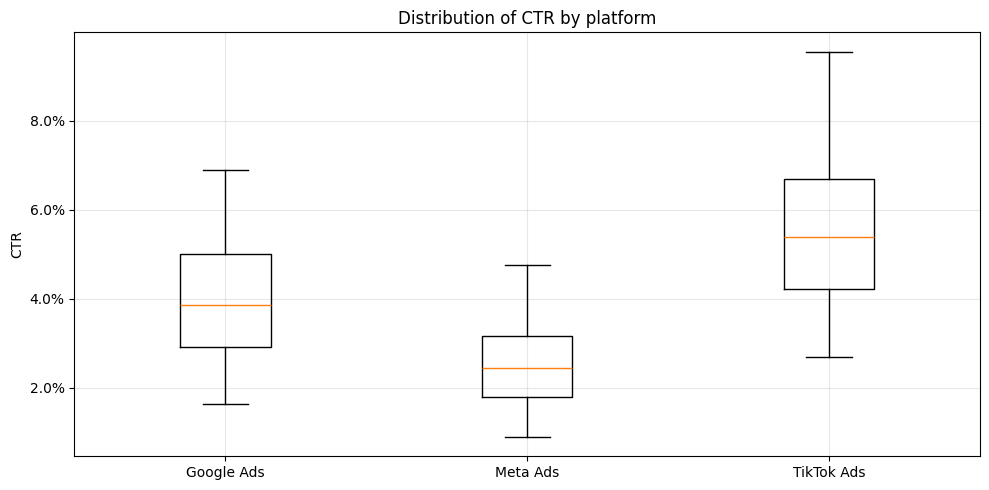

In [7]:
# Distribution of CTR per platform (boxplot)
if "CTR" in d and COLS["platform"]:
    groups, labels = [], []
    for name, grp in d.groupby(COLS["platform"]):
        vals = grp["CTR"].dropna()
        if len(vals) > 0:
            groups.append(vals); labels.append(str(name))
    plt.boxplot(groups, showfliers=False)
    plt.xticks(range(1, len(labels) + 1), labels)
    plt.title("Distribution of CTR by platform"); plt.ylabel("CTR")
    plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.1%}"))
    plt.tight_layout(); plt.savefig("figures/ctr_boxplot_platform.png", dpi=200); plt.show()

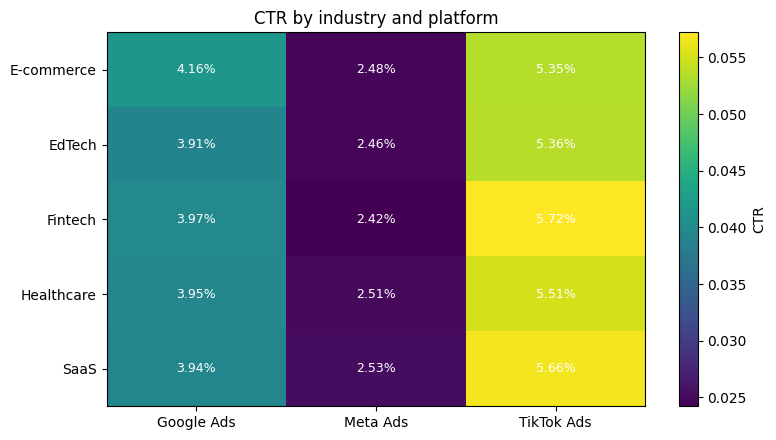

In [8]:
# Heatmap: platform x industry CTR — which platform works best for which market?
if COLS["platform"] and COLS["industry"] and COLS["impressions"] and COLS["clicks"]:
    p = d.groupby([COLS["industry"], COLS["platform"]])[[COLS["clicks"], COLS["impressions"]]].sum()
    heat = (p[COLS["clicks"]] / p[COLS["impressions"]]).unstack()
    fig, ax = plt.subplots(figsize=(8, 0.5 * len(heat) + 2))
    im = ax.imshow(heat.values, cmap="viridis", aspect="auto")
    ax.set_xticks(range(len(heat.columns)), heat.columns)
    ax.set_yticks(range(len(heat.index)), heat.index)
    for i in range(heat.shape[0]):
        for j in range(heat.shape[1]):
            v = heat.values[i, j]
            if not np.isnan(v):
                ax.text(j, i, f"{v:.2%}", ha="center", va="center", color="white", fontsize=9)
    ax.set_title("CTR by industry and platform"); ax.grid(False)
    fig.colorbar(im, ax=ax, label="CTR")
    plt.tight_layout(); plt.savefig("figures/ctr_heatmap.png", dpi=200); plt.show()

## 6. Are the differences real? (significance tests)
If CTR differs between platforms, is that difference bigger than random noise?
We use **ANOVA** (compares means) and **Kruskal–Wallis** (same idea, but doesn't assume a bell curve).
A p-value below 0.05 means the difference is statistically significant.

In [9]:
def compare_groups(metric, role):
    g = COLS[role]
    samples = [grp[metric].dropna() for _, grp in d.groupby(g) if grp[metric].notna().sum() > 2]
    if len(samples) < 2:
        return None
    f, p_anova = stats.f_oneway(*samples)
    h, p_kw = stats.kruskal(*samples)
    return {"group": role, "metric": metric, "ANOVA p": p_anova, "Kruskal p": p_kw,
            "significant (p<0.05)": "Yes" if p_kw < 0.05 else "No"}

tests = [compare_groups("CTR", r) for r in GROUPS]
tests2 = [compare_groups("CPC", r) for r in GROUPS]
tests_df = pd.DataFrame([t for t in tests if t])
tests2_df = pd.DataFrame([t for t in tests2 if t])
display(Markdown("## Significance tests (CTR)"))
display(tests_df)
display(Markdown("## Significance tests (CPC)"))
display(tests2_df)

## Significance tests (CTR)

,group,metric,ANOVA p,Kruskal p,significant (p<0.05)
0,platform,CTR,0.0000,0.0000,Yes
1,industry,CTR,0.2369,0.2233,No
2,country,CTR,0.6660,0.5401,No
3,campaign,CTR,0.4260,0.4523,No


## Significance tests (CPC)

,group,metric,ANOVA p,Kruskal p,significant (p<0.05)
0,platform,CPC,0.0000,0.0000,Yes
1,industry,CPC,0.7161,0.7293,No
2,country,CPC,0.6611,0.7827,No
3,campaign,CPC,0.4703,0.4842,No


## 7. Trends over time (regression)
We roll the data up to **monthly** totals per group, then fit a straight line (linear regression) to each group.
- **slope** = how much CTR changes per month (positive = rising)
- **R²** = how well a straight line fits (0 = not at all, 1 = perfectly)
- **p-value** < 0.05 = the trend is statistically significant

This handles the "multiple curves per group" challenge from the proposal: each group gets its own line and its own numbers, so you can compare them in one table.

In [10]:
assert COLS["date"], "No date column found — set COLS['date'] in the OVERRIDE cell to run trend analysis."
d["month"] = d[COLS["date"]].dt.to_period("M").dt.to_timestamp()

def monthly(role):
    g = COLS[role]
    agg = {COLS[r]: "sum" for r in ["impressions", "clicks", "spend"] if COLS[r]}
    m = d.groupby([g, "month"]).agg(agg).reset_index() if agg else d.groupby([g, "month"])["CTR"].mean().reset_index()
    if COLS["impressions"] and COLS["clicks"]:
        m["CTR"] = m[COLS["clicks"]] / m[COLS["impressions"]]
    return m

def trend_table(role, metric="CTR"):
    g = COLS[role]
    m = monthly(role)
    rows = []
    for name, grp in m.groupby(g):
        grp = grp.dropna(subset=[metric]).sort_values("month")
        if len(grp) < 4:
            continue
        x = np.arange(len(grp))  # month index 0,1,2,...
        res = stats.linregress(x, grp[metric])
        rows.append({g: name, "months": len(grp), "start": grp[metric].iloc[0], "end": grp[metric].iloc[-1],
                     "slope_per_month": res.slope, "R2": res.rvalue ** 2, "p_value": res.pvalue,
                     "trend": ("Rising" if res.slope > 0 else "Falling") if res.pvalue < 0.05 else "No significant trend"})
    return m, pd.DataFrame(rows).sort_values("slope_per_month", ascending=False)

trend_results = {}
for role in [r for r in ["platform", "industry"] if COLS[r]]:
    m, t = trend_table(role)
    trend_results[role] = (m, t)
    display(Markdown(f"## CTR trend by {role}"))
    display(t)

## CTR trend by platform

,platform,months,start,end,slope_per_month,R2,p_value,trend
1,Meta Ads,12,0.0250,0.0257,0.0002,0.1186,0.2731,No significant trend
2,TikTok Ads,12,0.0556,0.0535,0.0001,0.0155,0.7000,No significant trend
0,Google Ads,12,0.0363,0.0389,-0.0001,0.0189,0.6703,No significant trend


## CTR trend by industry

,industry,months,start,end,slope_per_month,R2,p_value,trend
0,E-commerce,12,0.0330,0.0362,0.0005,0.2866,0.0729,No significant trend
1,EdTech,12,0.0332,0.0423,0.0005,0.2339,0.1112,No significant trend
2,Fintech,12,0.0345,0.0383,0.0000,0.0016,0.9031,No significant trend
3,Healthcare,12,0.0352,0.0409,-0.0000,0.0028,0.8704,No significant trend
4,SaaS,12,0.0469,0.0371,-0.0005,0.2953,0.0679,No significant trend


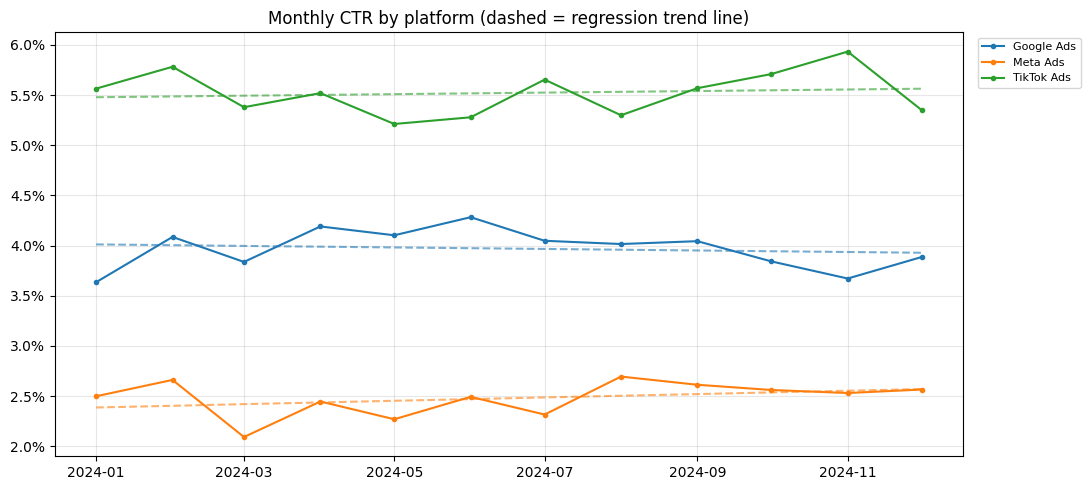

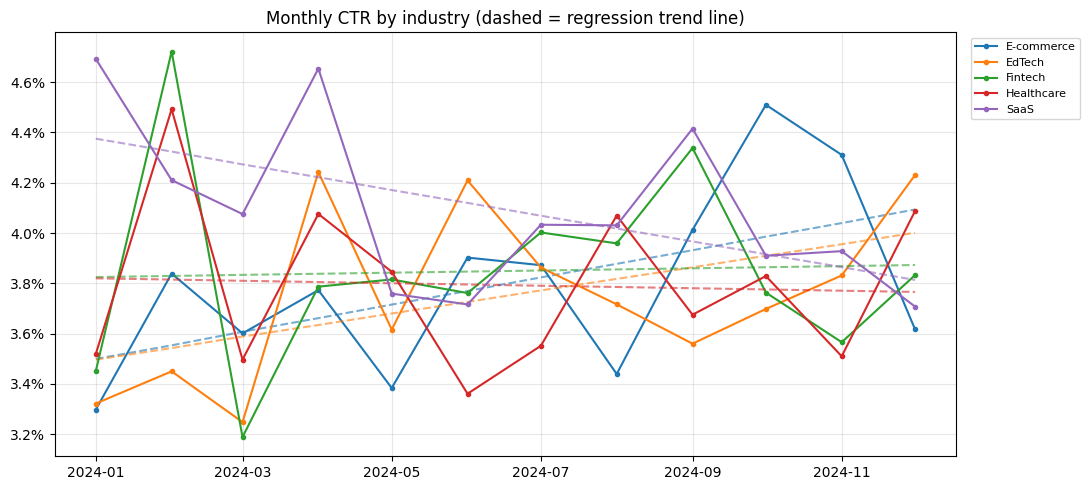

In [11]:
def plot_trend(role, metric="CTR"):
    g = COLS[role]
    m, t = trend_results[role]
    fig, ax = plt.subplots(figsize=(11, 5))
    for name, grp in m.groupby(g):
        grp = grp.sort_values("month")
        line, = ax.plot(grp["month"], grp[metric], marker="o", ms=3, label=str(name))
        x = np.arange(len(grp))
        if len(grp) >= 4:
            res = stats.linregress(x, grp[metric])
            ax.plot(grp["month"], res.intercept + res.slope * x, "--", color=line.get_color(), alpha=0.6)
    ax.set_title(f"Monthly {metric} by {role} (dashed = regression trend line)")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}"))
    ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
    plt.tight_layout(); plt.savefig(f"figures/trend_{metric}_{role}.png", dpi=200); plt.show()

for role in trend_results:
    plot_trend(role)

In [12]:
# Biggest month-over-month ups and downs per platform (the "history of ups/downs")
if "platform" in trend_results:
    m, _ = trend_results["platform"]
    g = COLS["platform"]
    m = m.sort_values([g, "month"])
    m["CTR_change"] = m.groupby(g)["CTR"].pct_change()
    swings = m.dropna(subset=["CTR_change"])
    display(Markdown("## Largest increases"))
    display(swings.nlargest(5, "CTR_change")[[g, "month", "CTR", "CTR_change"]])
    display(Markdown("## Largest decreases"))
    display(swings.nsmallest(5, "CTR_change")[[g, "month", "CTR", "CTR_change"]])

## Largest increases

,platform,month,CTR,CTR_change
15,Meta Ads,2024-04-01,0.0245,0.1691
19,Meta Ads,2024-08-01,0.0269,0.1635
1,Google Ads,2024-02-01,0.0409,0.1241
17,Meta Ads,2024-06-01,0.0249,0.0985
3,Google Ads,2024-04-01,0.0419,0.0921


## Largest decreases

,platform,month,CTR,CTR_change
14,Meta Ads,2024-03-01,0.0209,-0.2138
35,TikTok Ads,2024-12-01,0.0535,-0.0982
16,Meta Ads,2024-05-01,0.0227,-0.0722
18,Meta Ads,2024-07-01,0.0232,-0.0709
26,TikTok Ads,2024-03-01,0.0538,-0.0697


## 8. Key findings (auto-generated — rewrite these in your own words for the slides)

In [13]:
lines = []
for role, t in ranking_tables.items():
    if "weighted_CTR" in t:
        top, bot = t.index[0], t.index[-1]
        lines.append(f"- Highest CTR {role}: **{top}** ({t['weighted_CTR'].iloc[0]:.2%}); lowest: **{bot}** ({t['weighted_CTR'].iloc[-1]:.2%}).")
    if COLS["impressions"] in t:
        big = t[COLS["impressions"]].idxmax()
        lines.append(f"- Most total impressions by {role}: **{big}** ({t[COLS['impressions']].max():,.0f}).")
for _, r in tests_df.iterrows():
    lines.append(f"- {r['metric']} difference across {r['group']}: {'significant' if r['significant (p<0.05)']=='Yes' else 'NOT significant'} (Kruskal p = {r['Kruskal p']:.3g}).")
for role, (_, t) in trend_results.items():
    sig = t[t["trend"] != "No significant trend"]
    if len(sig):
        for _, r in sig.iterrows():
            lines.append(f"- {r[COLS[role]]}: {r['trend'].lower()} CTR trend ({r['slope_per_month']*100:+.3f} percentage points/month, p = {r['p_value']:.3g}).")
    else:
        lines.append(f"- No {role} shows a significant CTR trend over the period — differences *between* groups matter more than change over time.")
display(Markdown("\n\n".join(lines)))

- Highest CTR platform: **TikTok Ads** (5.53%); lowest: **Meta Ads** (2.48%).

- Most total impressions by platform: **Google Ads** (73,801,150).

- Highest CTR industry: **SaaS** (4.08%); lowest: **EdTech** (3.77%).

- Most total impressions by industry: **EdTech** (39,833,845).

- Highest CTR country: **Australia** (4.04%); lowest: **UK** (3.74%).

- Most total impressions by country: **USA** (27,665,597).

- Highest CTR campaign: **Search** (3.99%); lowest: **Display** (3.77%).

- Most total impressions by campaign: **Video** (47,748,617).

- CTR difference across platform: significant (Kruskal p = 3.3e-180).

- CTR difference across industry: NOT significant (Kruskal p = 0.223).

- CTR difference across country: NOT significant (Kruskal p = 0.54).

- CTR difference across campaign: NOT significant (Kruskal p = 0.452).

- No platform shows a significant CTR trend over the period — differences *between* groups matter more than change over time.

- No industry shows a significant CTR trend over the period — differences *between* groups matter more than change over time.

In [14]:
print("Charts saved in figures:", sorted(os.listdir("figures")))

Charts saved in figures: ['ctr_boxplot_platform.png', 'ctr_heatmap.png', 'trend_CTR_industry.png', 'trend_CTR_platform.png']
